# Классификация рентгенограмм лёгких: Normal / COVID-19 / Viral Pneumonia

**Задача:** построить модель классификации рентгеновских снимков грудной клетки на 3 класса и получить macro avg F1 ≥ 0.8 на тестовой выборке

**Подход:** transfer learning (ResNet18, предобучена на ImageNet), стратифицированное разбиение 70/15/15, аугментации на train, взвешенная функция потерь для борьбы с дисбалансом классов

**Результат:** macro avg F1 на тесте = **0.9877** (порог 0.8)


## 1. Анализ датасета

In [3]:
import os

dataset_path = "../project_dataset/"  

classes = ["Normal", "COVID", "Viral Pneumonia"]

for cls in classes:
    img_dir = os.path.join(dataset_path, cls, "images")
    files = os.listdir(img_dir)
    print(f"{cls}: {len(files)} файлов")
    print(f"  Пример: {files[0]}")

Normal: 10192 файлов
  Пример: Normal-6196.png
COVID: 3616 файлов
  Пример: COVID-1.png
Viral Pneumonia: 1345 файлов
  Пример: Viral Pneumonia-770.png


В датасете дисбаланс классов:
- Normal: 10192 (~66%)
- COVID: 3616 (~23%)
- Viral Pneumonia: 1345 (~9%)

Будем использовать стратификацию при разбивке. Возможно понадобится weighted loss или аугментации.

## 2. Разбивка на train/val/test со стратификацией

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

classes = ["Normal", "COVID", "Viral Pneumonia"]

# Собираем все пути и метки
data = []
for label, cls in enumerate(classes):
    img_dir = os.path.join(dataset_path, cls, "images")
    for fname in os.listdir(img_dir):
        if fname.endswith(".png") or fname.endswith(".jpg"):
            full_path = os.path.join(img_dir, fname)
            data.append({"path": full_path, "label": label, "class": cls})

df = pd.DataFrame(data)
print(f"Всего изображений: {len(df)}")
print(df["class"].value_counts())

# Разбивка: 70% train, 15% val, 15% test — стратифицированно
train_df, temp_df = train_test_split(
    df, test_size=0.3, random_state=42, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df["label"]
)

print(f"\nTrain: {len(train_df)}")
print(train_df["class"].value_counts())

print(f"\nVal:   {len(val_df)}")
print(val_df["class"].value_counts())

print(f"\nTest:  {len(test_df)}")
print(test_df["class"].value_counts())

Всего изображений: 15153
class
Normal             10192
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64

Train: 10607
class
Normal             7134
COVID              2531
Viral Pneumonia     942
Name: count, dtype: int64

Val:   2273
class
Normal             1529
COVID               542
Viral Pneumonia     202
Name: count, dtype: int64

Test:  2273
class
Normal             1529
COVID               543
Viral Pneumonia     201
Name: count, dtype: int64


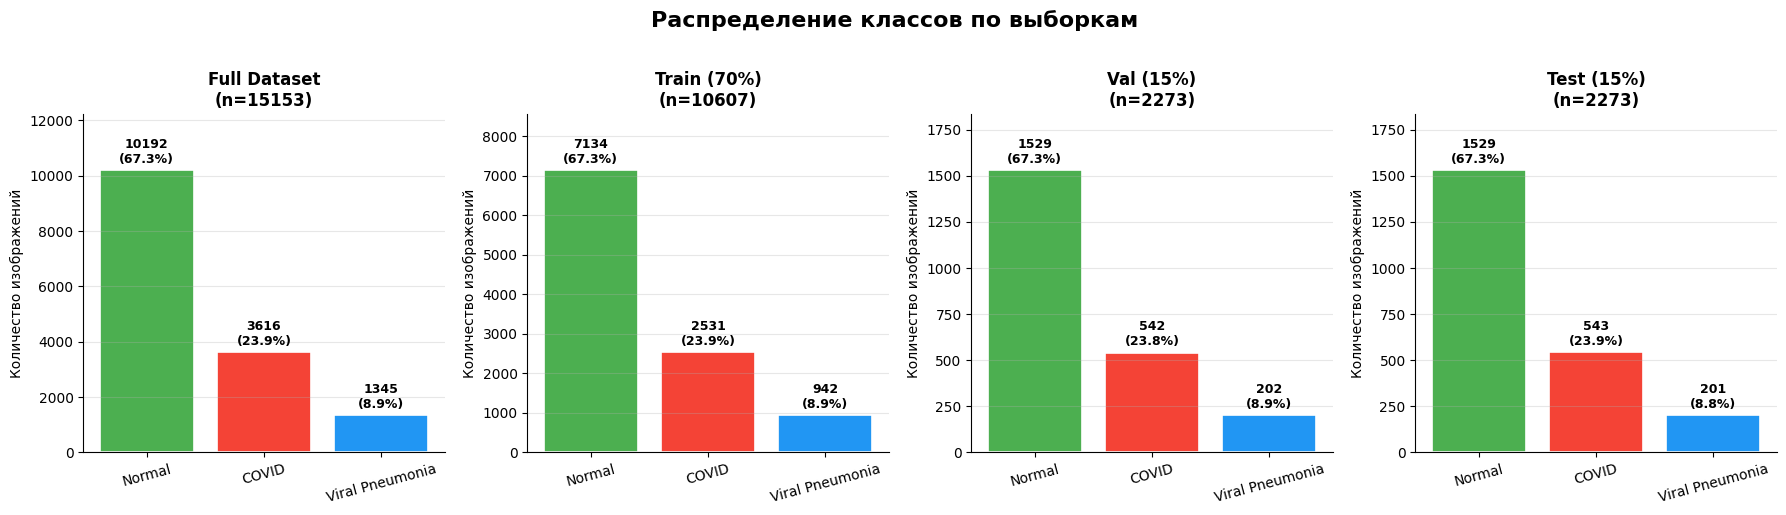

График сохранён: ../figures/class_distribution.png


In [10]:
#Визуализация распределения классов
import matplotlib.pyplot as plt
import numpy as np

classes = ["Normal", "COVID", "Viral Pneumonia"]
colors = ["#4CAF50", "#F44336", "#2196F3"]

fig_dir = "../figures"

splits = {
    "Full Dataset": df,
    "Train (70%)": train_df,
    "Val (15%)": val_df,
    "Test (15%)": test_df,
}

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle("Распределение классов по выборкам", fontsize=16, fontweight="bold", y=1.02)

for ax, (split_name, split_df) in zip(axes, splits.items()):
    counts = [len(split_df[split_df["class"] == cls]) for cls in classes]
    total = sum(counts)
    bars = ax.bar(classes, counts, color=colors, edgecolor="white", linewidth=1.2)

    # Подписи значений и процентов над столбцами
    for bar, count in zip(bars, counts):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + total * 0.01,
            f"{count}\n({count/total*100:.1f}%)",
            ha="center", va="bottom", fontsize=9, fontweight="bold"
        )

    ax.set_title(f"{split_name}\n(n={total})", fontsize=12, fontweight="bold")
    ax.set_ylabel("Количество изображений")
    ax.set_ylim(0, max(counts) * 1.2)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(f"{fig_dir}/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"График сохранён: {fig_dir}/class_distribution.png")

**Вывод:** Разбивка прошла успешно. Распределение классов сохранилось во всех выборках (~67% / ~24% / ~9%) — стратификация работает корректно

## 3. PyTorch Dataset и DataLoaders

Выполняем трансформации для train с аугментацией, для val/test без.

Train — аугментации нужны, потому что:
- Модель должна научиться распознавать паттерны в разных условиях
- Искусственно увеличиваем разнообразие данных (особенно важно для Viral Pneumonia — там всего 942 примера)
- Снижает переобучение (overfitting)

Val/Test — аугментации НЕ нужны, потому что:
- Val и Test имитируют реальные условия — мы оцениваем модель на "чистых" данных
- Если применить случайные трансформации на val, метрики будут нестабильны от эпохи к эпохе (каждый раз разные картинки)
- Test — это финальная честная оценка, результат должен быть воспроизводимым

In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Трансформации для train (с аугментацией) и val/test (без)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),  # рентген = grayscale, но модели ждут 3 канала
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# PyTorch Dataset
class XRayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "path"]
        label = self.df.loc[idx, "label"]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

# Создаём датасеты
train_dataset = XRayDataset(train_df, transform=train_transforms)
val_dataset   = XRayDataset(val_df,   transform=val_test_transforms)
test_dataset  = XRayDataset(test_df,  transform=val_test_transforms)

# Создаём DataLoaders (num_workers=0 для macOS)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=0)

# Проверка
batch_imgs, batch_labels = next(iter(train_loader))
print(f"Batch images shape: {batch_imgs.shape}")
print(f"Batch labels shape: {batch_labels.shape}")
print(f"Уникальные метки в батче: {batch_labels.unique()}")
print(f"\nTrain batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")
print(f"Test batches:  {len(test_loader)}")

Batch images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])
Уникальные метки в батче: tensor([0, 1, 2])

Train batches: 332
Val batches:   72
Test batches:  72


## 4. Модель, цикл обучения и валидации

In [7]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import classification_report
import copy

# Устройство
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Устройство: {device}")

# Модель
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 3)
model = model.to(device)
print("Модель загружена успешно!")

# LOSS с учетом дисбаланса
class_counts = torch.tensor([10192, 3616, 1345], dtype=torch.float)
class_weights = 1.0 / class_counts
class_weights = class_weights / class_weights.sum()
class_weights = class_weights.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

Устройство: mps
Модель загружена успешно!


### Запуск обучения

In [8]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=10):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_f1 = 0.0
    history = {"train_loss": [], "val_loss": [], "val_f1": []}

    for epoch in range(num_epochs):
        # TRAIN
        model.train()
        train_loss = 0.0

        for i, (imgs, labels) in enumerate(train_loader):
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * imgs.size(0)

            if (i + 1) % 50 == 0:
                print(f"  Epoch {epoch+1} | Batch {i+1}/{len(train_loader)} | Loss: {loss.item():.4f}")

        train_loss /= len(train_loader.dataset)

        # VALIDATION
        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * imgs.size(0)
                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader.dataset)
        report = classification_report(
            all_labels, all_preds,
            target_names=classes,
            output_dict=True,
            zero_division=0
        )
        val_f1 = report["macro avg"]["f1-score"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)

        print(f"\nEpoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val macro F1: {val_f1:.4f}\n")

        # Сохраняем лучшую модель по val F1
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(best_model_wts, "best_model.pth")
            print(f"  ✓ Лучшая модель сохранена (val F1={best_val_f1:.4f})\n")

        scheduler.step()

    print(f"Обучение завершено. Лучший val macro F1: {best_val_f1:.4f}")
    model.load_state_dict(best_model_wts)
    return model, history

# Запуск обучения
model, history = train_model(
    model, train_loader, val_loader,
    criterion, optimizer, scheduler,
    num_epochs=10
)

  Epoch 1 | Batch 50/332 | Loss: 0.7705
  Epoch 1 | Batch 100/332 | Loss: 0.2624
  Epoch 1 | Batch 150/332 | Loss: 0.3872
  Epoch 1 | Batch 200/332 | Loss: 0.1930
  Epoch 1 | Batch 250/332 | Loss: 0.1685
  Epoch 1 | Batch 300/332 | Loss: 0.1062

Epoch [1/10] Train Loss: 0.2158 | Val Loss: 0.0912 | Val macro F1: 0.9208

  ✓ Лучшая модель сохранена (val F1=0.9208)

  Epoch 2 | Batch 50/332 | Loss: 0.3991
  Epoch 2 | Batch 100/332 | Loss: 0.4232
  Epoch 2 | Batch 150/332 | Loss: 0.1194
  Epoch 2 | Batch 200/332 | Loss: 0.1461
  Epoch 2 | Batch 250/332 | Loss: 0.0329
  Epoch 2 | Batch 300/332 | Loss: 0.0165

Epoch [2/10] Train Loss: 0.0957 | Val Loss: 0.0575 | Val macro F1: 0.9736

  ✓ Лучшая модель сохранена (val F1=0.9736)

  Epoch 3 | Batch 50/332 | Loss: 0.0308
  Epoch 3 | Batch 100/332 | Loss: 0.1580
  Epoch 3 | Batch 150/332 | Loss: 0.0474
  Epoch 3 | Batch 200/332 | Loss: 0.0243
  Epoch 3 | Batch 250/332 | Loss: 0.0714
  Epoch 3 | Batch 300/332 | Loss: 0.0145

Epoch [3/10] Train Los

**Ключевые наблюдения:**
Val macro F1 = 0.9904 (лучшая эпоха — 8) очень высокий, вызывает подозрения.

Возможные причины:
1. Transfer Learning — главная причина
ResNet18 уже обучен на ImageNet (миллионы картинок). Он умеет извлекать базовые признаки (края, текстуры, формы), поэтому осталось только "донастроить" под рентген (fine-tuning) и это дало очень высокие результаты даже за 10 эпох
2. Данные относительно "чистые"
Рентген-снимки трёх классов визуально довольно различимы — у COVID, пневмонии и нормы разные паттерны в лёгких. Это не сложная задача для сильной модели
3. Учтен дисбаланс классов
class_weights в loss функции помог модели не игнорировать редкий класс Viral Pneumonia (всего 942 примера в трейне)

Но это не похоже на переобучение:
- Train loss снижается стабильно (0.216 → 0.015), Val loss в целом тоже (0.091 → 0.028), но не монотонно: небольшие подъёмы на эпохах 3, 6 и 9
- Val macro F1 тоже колеблется (например, 0.9736 на эпохе 2 → 0.9392 на эпохе 3), но с 6-й эпохи держится на уровне 0.985–0.990
- Лучшая эпоха выбирается по val, поэтому 0.9904 — слегка оптимистичная оценка. Реалистичную оценку даст отложенный test (см. ниже)

Оговорка: в публичных датасетах рентгенограмм встречаются дубликаты и общие источники снимков, поэтому часть высокого качества может объясняться их попаданием в разные выборки. Проверка на дубликаты не проводилась (см. conclusions.md, раздел «Ограничения»)

## Финальные метрики на тестовой выборке и визуализация результатов

In [11]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Метрики
from sklearn.metrics import confusion_matrix

report_dict = classification_report(
    all_labels, all_preds,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(all_labels, all_preds)

# Подсчёт ошибок
errors = {}
for i, cls in enumerate(classes):
    total = cm[i].sum()
    wrong = total - cm[i][i]
    errors[cls] = {"total": int(total), "wrong": int(wrong), "pct": wrong / total * 100}

# Вывод таблицы
print("=" * 75)
print("Метрики на тестовой выборке")
print("=" * 75)
print(f"{'Класс':<20} {'Precision':>10} {'Recall':>10} {'F1-score':>10} {'Ошибок':>12} {'% ошибок':>10}")
print("-" * 75)

for cls in classes:
    p  = report_dict[cls]['precision']
    r  = report_dict[cls]['recall']
    f1 = report_dict[cls]['f1-score']
    w  = errors[cls]['wrong']
    t  = errors[cls]['total']
    pct = errors[cls]['pct']
    print(f"{cls:<20} {p:>10.4f} {r:>10.4f} {f1:>10.4f} {f'{w}/{t}':>12} {pct:>9.2f}%")

print("-" * 75)
ma_p  = report_dict['macro avg']['precision']
ma_r  = report_dict['macro avg']['recall']
ma_f1 = report_dict['macro avg']['f1-score']
print(f"{'macro avg':<20} {ma_p:>10.4f} {ma_r:>10.4f} {ma_f1:>10.4f}")
print("=" * 75)
print(f"\nmacro avg F1 = {ma_f1:.4f}")

Метрики на тестовой выборке
Класс                 Precision     Recall   F1-score       Ошибок   % ошибок
---------------------------------------------------------------------------
Normal                   0.9954     0.9935     0.9944      10/1529      0.65%
COVID                    0.9908     0.9908     0.9908        5/543      0.92%
Viral Pneumonia          0.9706     0.9851     0.9778        3/201      1.49%
---------------------------------------------------------------------------
macro avg                0.9856     0.9898     0.9877

macro avg F1 = 0.9877


**Ключевые наблюдения:**
- macro avg F1 = 0.9877. Результаты на val (0.9904) и test (0.9877) очень близки, значит модель не переобучилась
- Viral Pneumonia слабее остальных по F1 (0.9778), что логично: в тесте всего 201 пример. Главная причина здесь Precision (0.9706): модель немного чаще выдаёт этот диагноз ошибочно, чем пропускает его (Recall 0.9851)
- Normal показывает лучший результат (F1 = 0.9944), данных этого класса больше всего

### Визуализация результатов

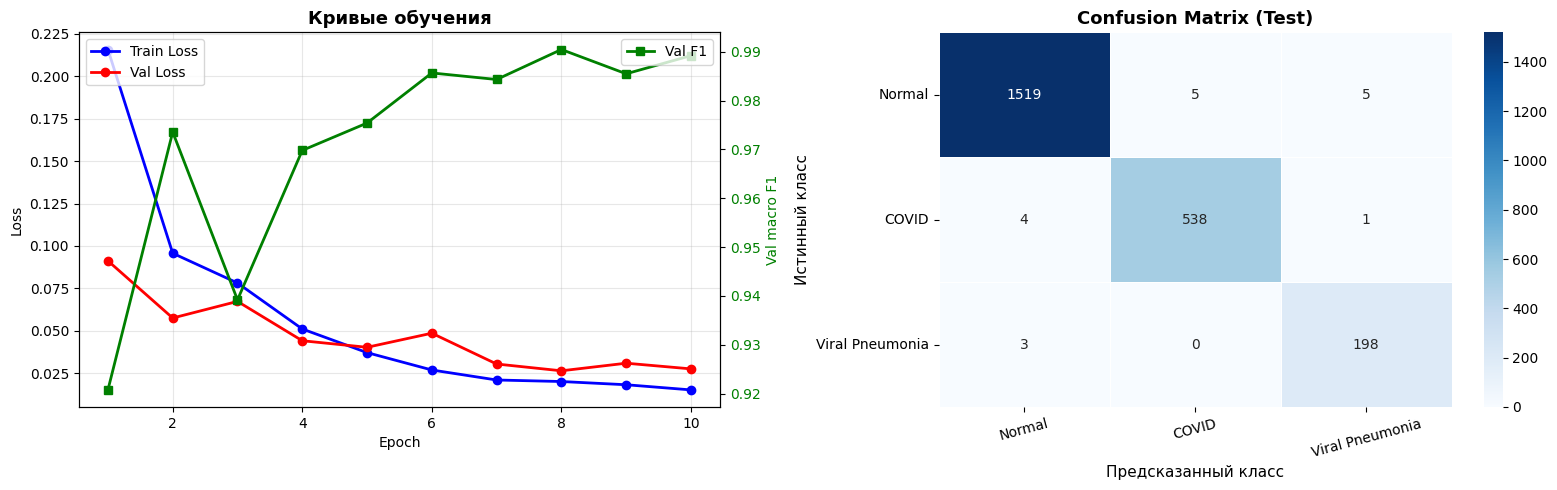

График сохранён: ../figures/results.png


In [12]:
import seaborn as sns
from sklearn.metrics import confusion_matrix


fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Кривые обучения
ax1 = axes[0]
epochs = range(1, len(history["train_loss"]) + 1)
ax1.plot(epochs, history["train_loss"], "b-o", label="Train Loss", linewidth=2)
ax1.plot(epochs, history["val_loss"],   "r-o", label="Val Loss",   linewidth=2)
ax1_twin = ax1.twinx()
ax1_twin.plot(epochs, history["val_f1"], "g-s", label="Val F1", linewidth=2)
ax1_twin.set_ylabel("Val macro F1", color="green")
ax1_twin.tick_params(axis="y", labelcolor="green")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Кривые обучения", fontsize=13, fontweight="bold")
ax1.legend(loc="upper left")
ax1_twin.legend(loc="upper right")
ax1.grid(alpha=0.3)

# Confusion Matrix
ax2 = axes[1]
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=classes, yticklabels=classes,
    ax=ax2, linewidths=0.5
)
ax2.set_xlabel("Предсказанный класс", fontsize=11)
ax2.set_ylabel("Истинный класс", fontsize=11)
ax2.set_title("Confusion Matrix (Test)", fontsize=13, fontweight="bold")
ax2.tick_params(axis="x", rotation=15)
ax2.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(f"{fig_dir}/results.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"График сохранён: {fig_dir}/results.png")

#### Ключевые наблюдения

**Кривые обучения (левый график):**
- Train Loss стабильно снижается (0.216 → 0.015), Val Loss в целом тоже (0.091 → 0.028). Небольшие подъёмы Val Loss на эпохах 3, 6 и 9 не привели к устойчивому ухудшению качества
- Val F1 растёт с 0.92 до 0.99. Заметная просадка на эпохе 3 (0.939), с 6-й эпохи значение держится на уровне 0.985–0.990
- Явного переобучения нет: разрыв между Train Loss и Val Loss небольшой, а качество на test (0.9877) близко к val (0.9904)

**Confusion Matrix (правый график, тест):**
- Normal: 1519 из 1529 верно, 10 ошибок (5 COVID, 5 Viral Pneumonia)
- COVID: 538 из 543 верно, 5 ошибок (4 Normal, 1 Viral Pneumonia)
- Viral Pneumonia: 198 из 201 верно, 3 ошибки (все 3 Normal)

## Общие выводы

### Модель
- **Архитектура:** ResNet18 (Transfer Learning, ImageNet)
- **Устройство:** MPS (Apple Silicon)
- **Лучшая эпоха:** 8 из 10
- **Выбор модели:** по macro avg F1 на валидационной выборке

### Общий вывод

- **macro avg F1 = 0.9877**
- Модель демонстрирует высокое качество классификации. COVID показывает Recall = 0.9908: модель пропускает менее 1% больных. Viral Pneumonia показывает Recall = 0.9851: модель пропускает около 1.5% больных, это самый низкий Recall среди классов, но разница с остальными небольшая. У этого же класса самый низкий Precision (0.9706): 6 снимков других классов ошибочно признаны вирусной пневмонией. Слабее результат объясняется наименьшей представленностью класса в обучающей выборке (942 примера)


> ⚠️ Модель пригодна как инструмент **первичного скрининга** для помощи врачу.
> Финальный диагноз должен ставиться только квалифицированным специалистом.

### Анализ ошибок в медицинском контексте

В медицинской диагностике ошибки делятся на два типа:

- **False Negative (пропуск болезни)** - модель сказала "здоров". Пациент болен, что **критично**: пациент не получит лечение вовремя
- **False Positive (ложная тревога)** - модель сказала "болен". Пациент здоров, что менее критично: приведёт к дополнительным обследованиям

#### COVID-19, Recall = 0.9908

Ошибочно классифицировано **5 из 543** случаев COVID (0.92%): 4 из них признаны здоровыми (настоящий пропуск), 1 — вирусной пневмонией. Модель находит **99.1% всех случаев COVID**

Пропуск COVID особенно опасен: нераспознанный пациент продолжает контактировать с окружающими и не получает лечения. Из 100 больных модель пропустит около одного. Результат приемлем для задач первичного скрининга

#### Viral Pneumonia, Recall = 0.9851

Пропущено **3 из 201** больных (1.49%), все три признаны здоровыми. Модель находит **98.5% всех случаев пневмонии**

Это самый низкий Recall среди классов, что объясняется наименьшим количеством обучающих данных (942 примера в трейне). Пропуск пневмонии критичен: без лечения состояние пациента быстро ухудшается. Кроме того, Precision у этого класса самый низкий (0.9706), поэтому для него желательно собрать больше данных или усилить аугментацию. Оценка по классу также статистически шумная: в тесте всего 201 пример, и одна ошибка меняет Recall примерно на 0.5 п.п

#### Normal, Recall = 0.9935

Ошибочно признано больными **10 из 1529** здоровых (0.65%): 5 как COVID и 5 как вирусная пневмония. Модель верно определяет **99.4% здоровых пациентов**

False Positive для здорового класса наименее опасен: пациент пройдёт дополнительное обследование, но не останется без помощи. 10 ложных тревог из 1529 — минимальная нагрузка на систему

#### Итого по «пропуску болезни»

Больных (COVID + Viral Pneumonia) в тесте 744. Признаны здоровыми **7** (4 + 3), то есть **0.94%**. Это самая клинически значимая ошибка модели и главный ориентир для дальнейшего улучшения (например, через калибровку порога по Recall для болезни). Всего на тесте 18 ошибок из 2 273 снимков